# 2. Pre-processing and classification
We use a stratified 80/20 train/test split (120,000 train, 30,000 test). For leakage-free model selection and computational efficiency on local hardware, candidate models are trained on a 20,000-instance training sample (which empirically preserves the class distribution: 76.6% Slight, 21.9% Serious, 1.5% Fatal) drawn from the pre-test training pool, and benchmarked on a 24,000-instance validation split. Classifiers are compared on the validation split using Accuracy, Macro F1, Fatal Recall, Serious Recall, and a safety-weighted Selection Score. The selected best model is then refitted on the full 120,000-instance training set and evaluated once on the untouched 30,000-sample held-out test split.

Candidate training sample: 20,000; validation: 24,000; final test: 30,000
Validation-selected model: Logistic Regression | tuned Logistic Regression C: {'model__C': 1}
Untouched-test metrics: {'model': 'Logistic Regression', 'accuracy': 0.5182333333333333, 'macro_precision': 0.3806922592183344, 'macro_recall': 0.49472679834928507, 'macro_f1': 0.33975784848853713, 'fatal_recall': 0.6501128668171557, 'serious_recall': 0.23867622388287327, 'selection_score': 0.6142734695942831}


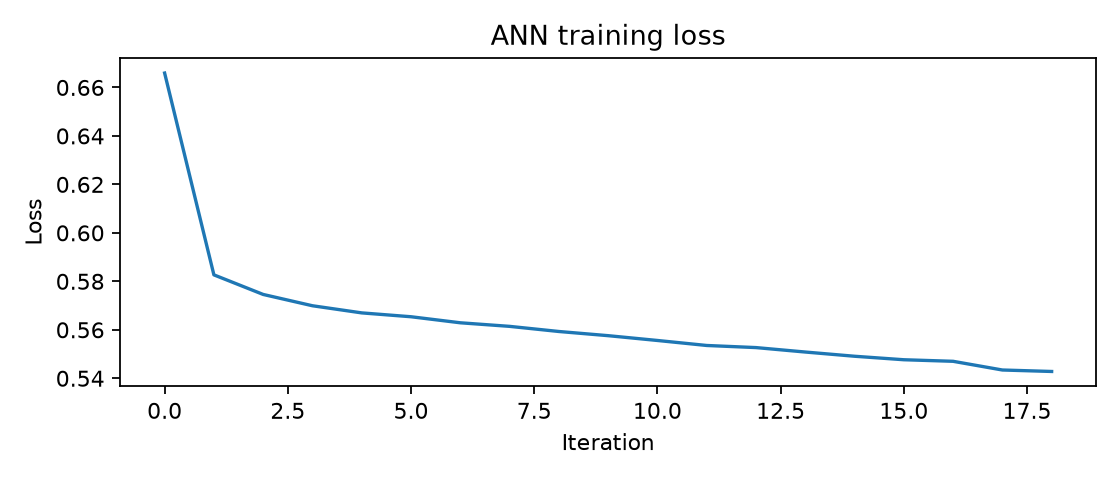

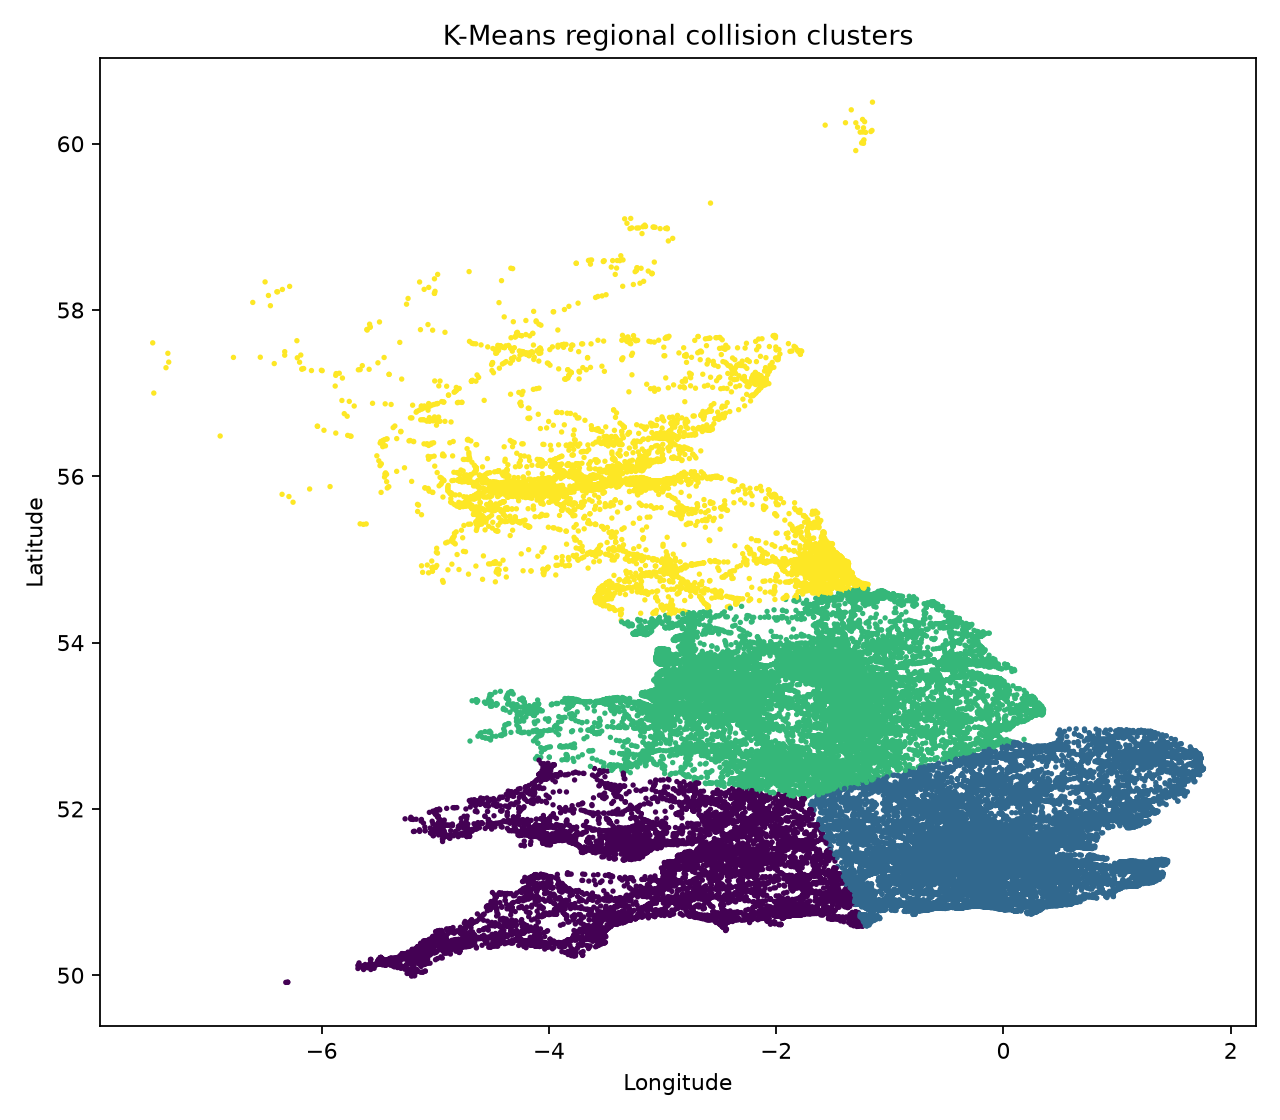

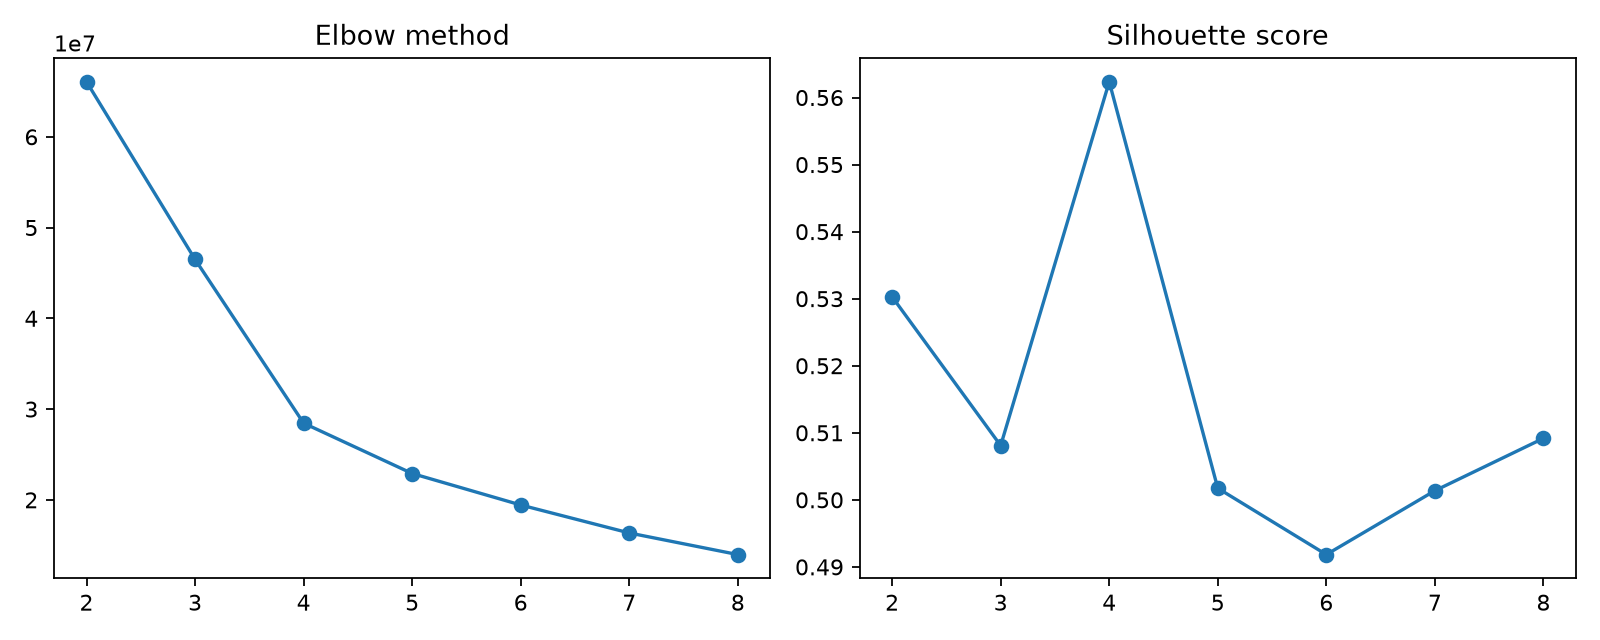

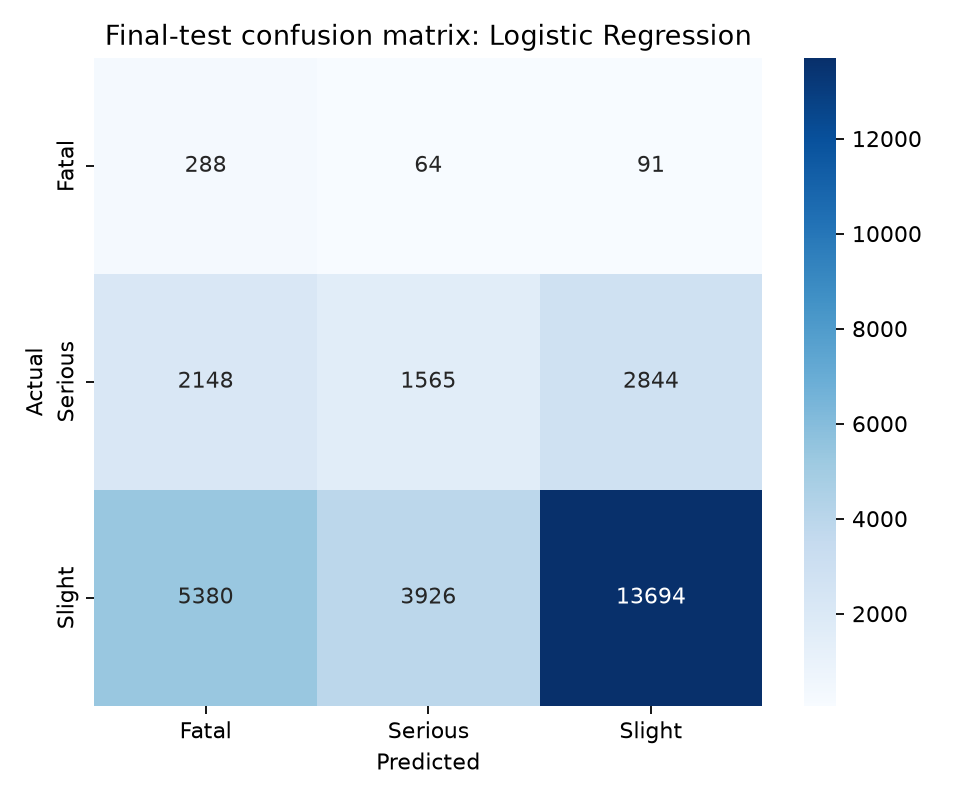

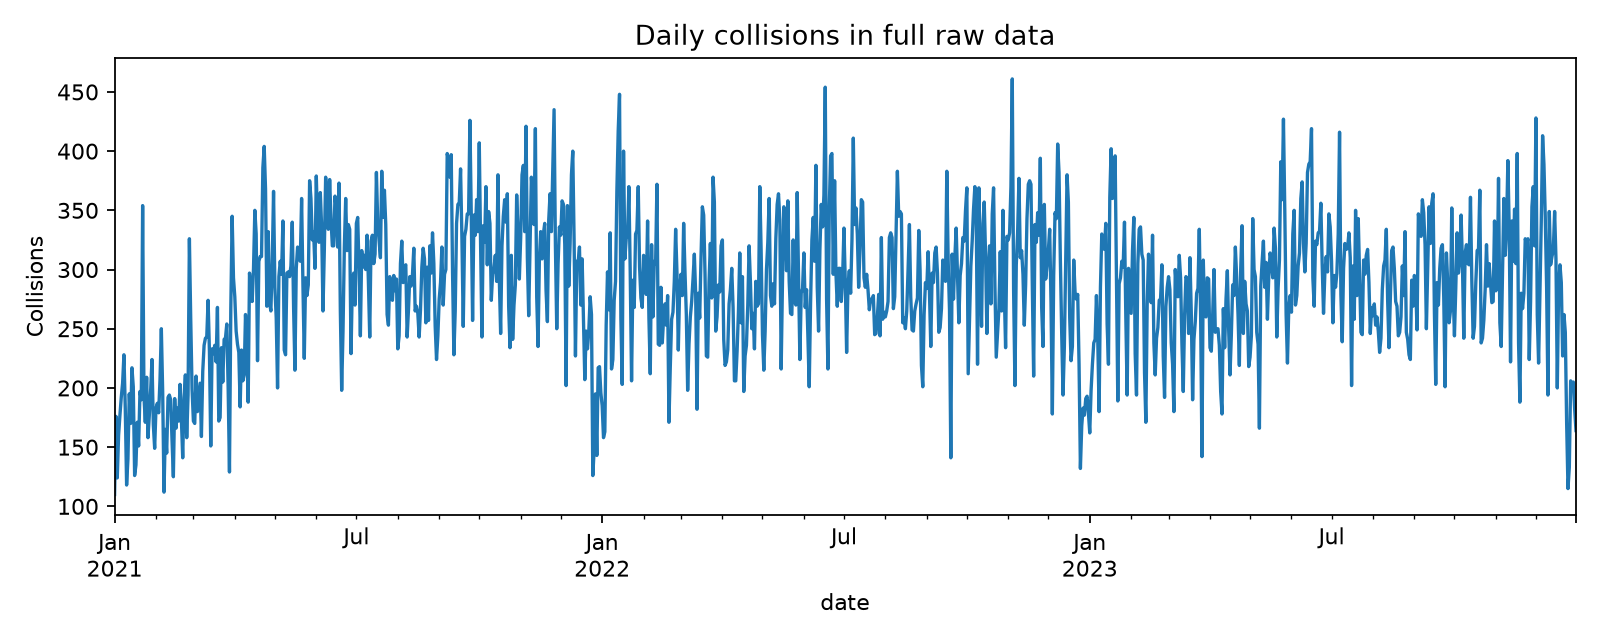

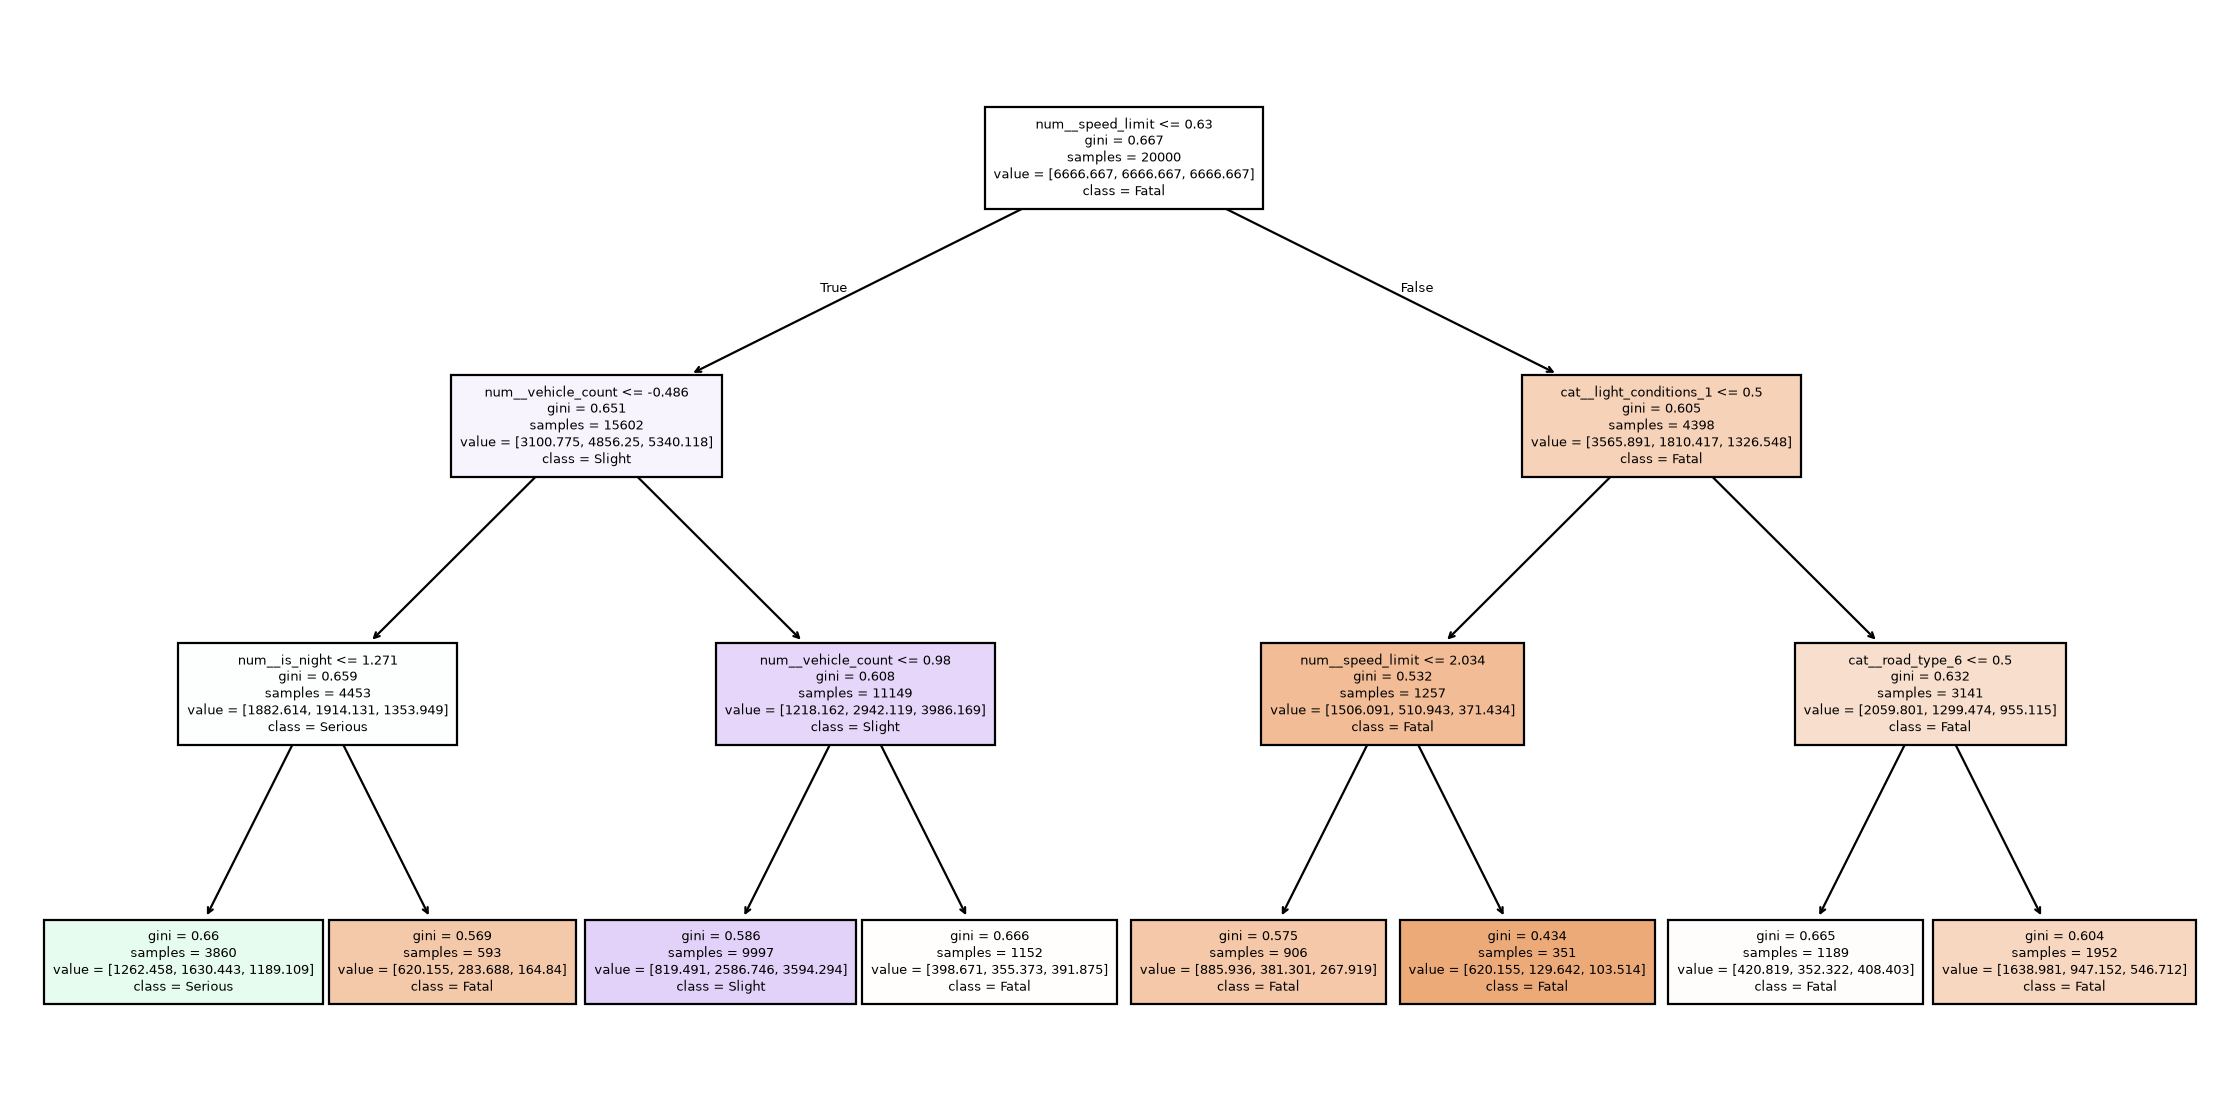

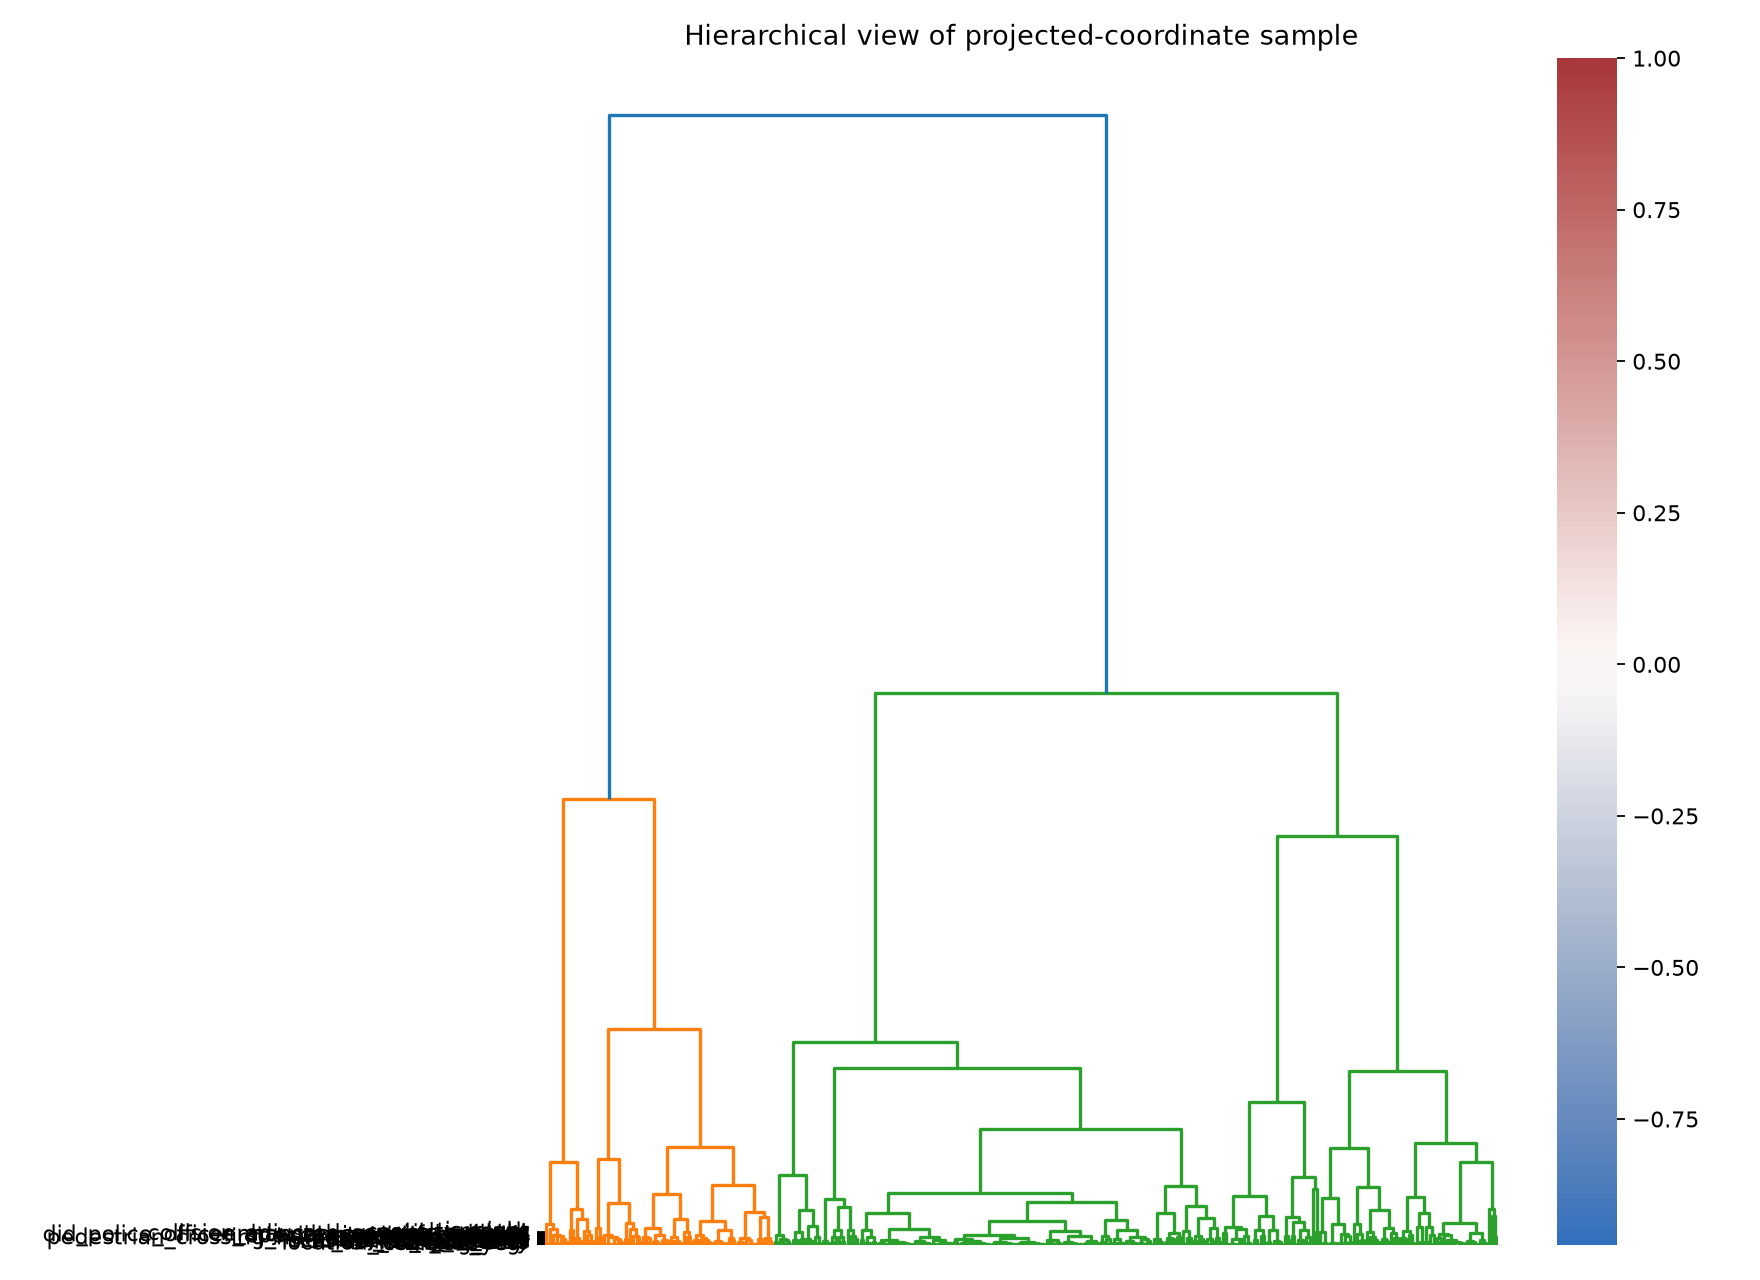

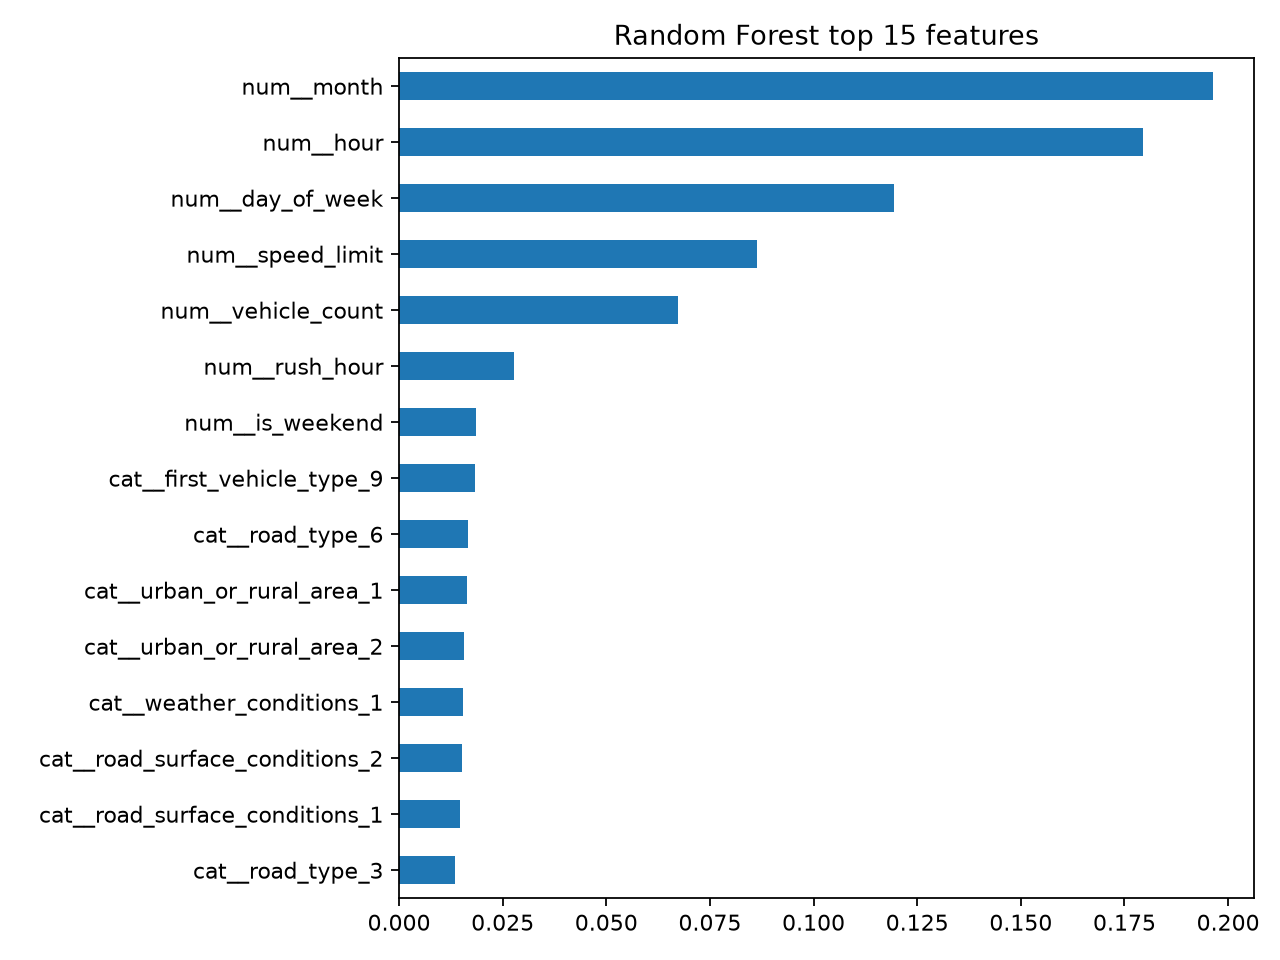

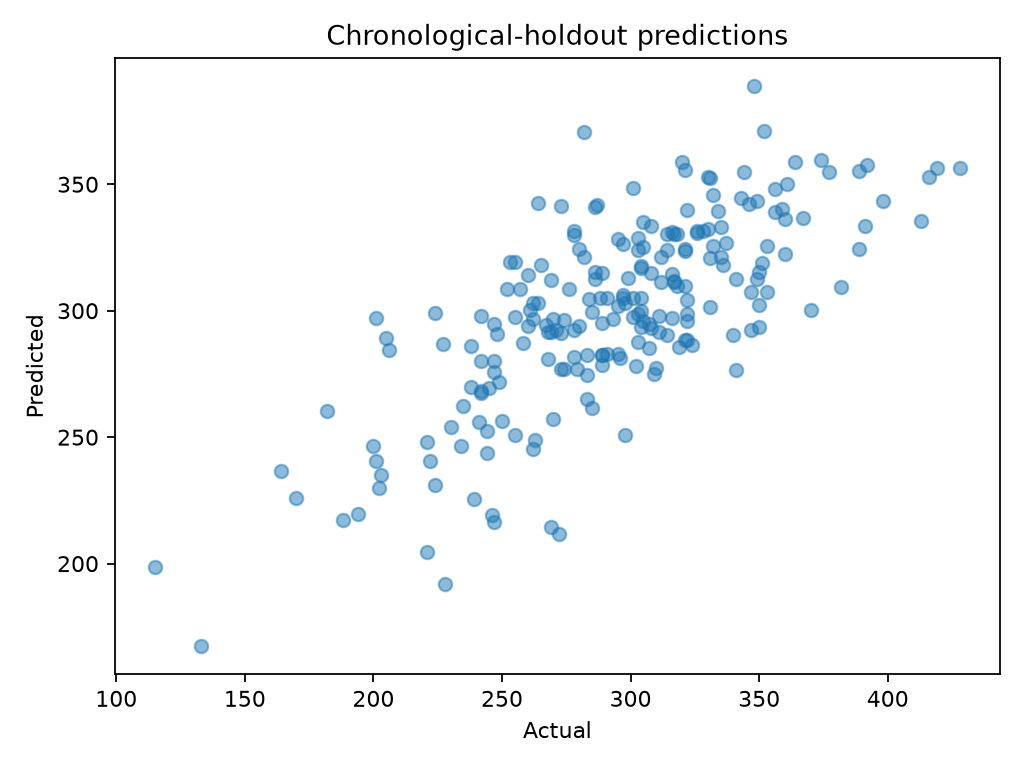

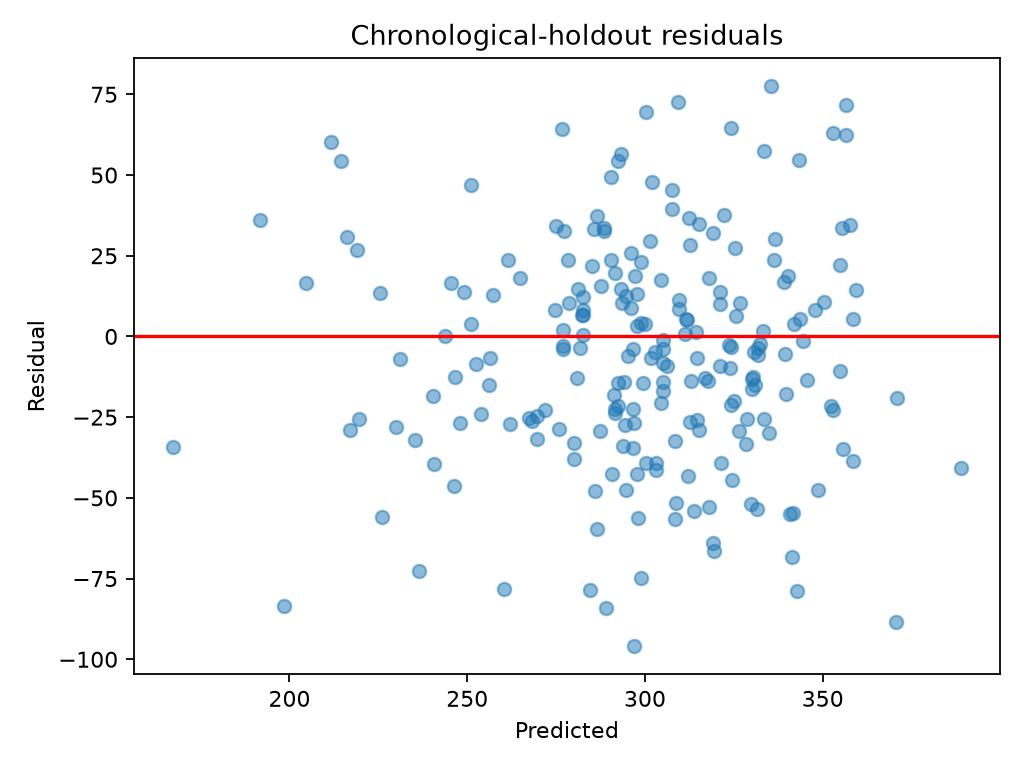

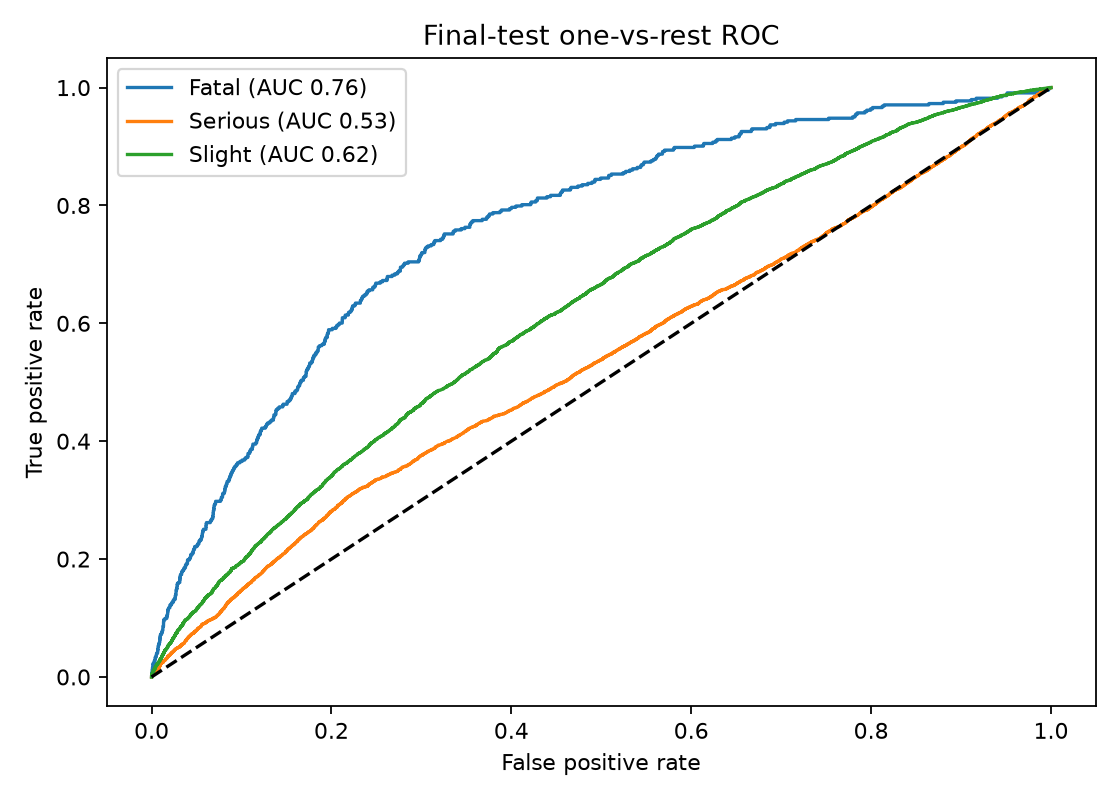

In [2]:
from pathlib import Path
import json, time
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_curve, auc
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone
from imblearn.over_sampling import SMOTE
from joblib import dump

ROOT = Path.cwd().resolve()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
df = pd.read_csv(ROOT / 'data/processed/cleaned_accidents.csv')
features = ['hour','day_of_week','month','is_weekend','is_night','rush_hour','weather_conditions','light_conditions','road_type','speed_limit','road_surface_conditions','urban_or_rural_area','vehicle_count','first_vehicle_type']
cat = ['weather_conditions','light_conditions','road_type','road_surface_conditions','urban_or_rural_area','first_vehicle_type']
num = [c for c in features if c not in cat]
X, y = df[features], df.severity

# The final 20% is reserved until after model selection and tuning.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42, stratify=y)
X_pool, X_val, y_pool, y_val = train_test_split(X_train, y_train, test_size=.2, random_state=42, stratify=y_train)
candidate_size = min(20000, len(X_pool))
candidate_idx = X_pool.sample(candidate_size, random_state=42).index
X_fit, y_fit = X_pool.loc[candidate_idx], y_pool.loc[candidate_idx]
print(f'Candidate training sample: {len(X_fit):,}; validation: {len(X_val):,}; final test: {len(X_test):,}')

prep = ColumnTransformer([
    ('num', StandardScaler(), num),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat)
])
models = {
    'Logistic Regression': LogisticRegression(max_iter=400, class_weight='balanced'),
    'Tree Gini': DecisionTreeClassifier(criterion='gini', class_weight='balanced', random_state=42),
    'Tree Entropy': DecisionTreeClassifier(criterion='entropy', class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1),
    'Naive Bayes': GaussianNB(),
    'KNN': KNeighborsClassifier(n_neighbors=7),
    'SVM': SVC(class_weight='balanced', probability=True, random_state=42),
    'ANN': MLPClassifier(hidden_layer_sizes=(64,32), max_iter=100, early_stopping=True, random_state=42)
}

results, fitted, validation_predictions = [], {}, {}
labels = sorted(y.unique())
for name, estimator in models.items():
    pipe = Pipeline([('prep', clone(prep)), ('model', estimator)])
    start = time.time()
    pipe.fit(X_fit, y_fit)
    training_seconds = time.time() - start
    pred = pipe.predict(X_val)
    validation_predictions[name] = pred
    report = classification_report(y_val, pred, output_dict=True, zero_division=0)
    results.append({
        'model': name,
        'accuracy': accuracy_score(y_val, pred),
        'macro_precision': precision_score(y_val, pred, average='macro', zero_division=0),
        'macro_recall': recall_score(y_val, pred, average='macro', zero_division=0),
        'macro_f1': f1_score(y_val, pred, average='macro', zero_division=0),
        'fatal_recall': report.get('Fatal', {}).get('recall', 0),
        'serious_recall': report.get('Serious', {}).get('recall', 0),
        'training_seconds': training_seconds
    })
    fitted[name] = pipe

scores = pd.DataFrame(results)
scores['selection_score'] = (scores.fatal_recall + scores.serious_recall + scores.macro_f1) / 2

# Tune Logistic Regression only on the candidate-training data and validate it once.
search = GridSearchCV(
    Pipeline([('prep', clone(prep)), ('model', LogisticRegression(max_iter=400, class_weight='balanced'))]),
    {'model__C': [0.5, 1, 2]}, cv=3, scoring='f1_macro', n_jobs=-1
)
search.fit(X_fit, y_fit)
tuned_lr = search.best_estimator_
tuned_pred = tuned_lr.predict(X_val)
tuned_report = classification_report(y_val, tuned_pred, output_dict=True, zero_division=0)
lr_mask = scores.model.eq('Logistic Regression')
scores.loc[lr_mask, ['accuracy','macro_precision','macro_recall','macro_f1','fatal_recall','serious_recall']] = [
    accuracy_score(y_val, tuned_pred),
    precision_score(y_val, tuned_pred, average='macro', zero_division=0),
    recall_score(y_val, tuned_pred, average='macro', zero_division=0),
    f1_score(y_val, tuned_pred, average='macro', zero_division=0),
    tuned_report['Fatal']['recall'], tuned_report['Serious']['recall']
]
validation_predictions['Logistic Regression'] = tuned_pred
fitted['Logistic Regression'] = tuned_lr
scores['selection_score'] = (scores.fatal_recall + scores.serious_recall + scores.macro_f1) / 2
scores = scores.sort_values('selection_score', ascending=False)
scores.to_csv(ROOT / 'outputs/tables/classification_metrics.csv', index=False)
best_name = scores.iloc[0].model
print('Validation-selected model:', best_name, '| tuned Logistic Regression C:', search.best_params_)

# Refit the selected pipeline on all pre-test observations, then evaluate the untouched test set once.
if best_name == 'Logistic Regression':
    best = clone(tuned_lr).fit(X_train, y_train)
else:
    best = clone(fitted[best_name]).fit(X_train, y_train)
test_pred = best.predict(X_test)
test_report = classification_report(y_test, test_pred, output_dict=True, zero_division=0)
test_metrics = {
    'model': best_name,
    'accuracy': accuracy_score(y_test, test_pred),
    'macro_precision': precision_score(y_test, test_pred, average='macro', zero_division=0),
    'macro_recall': recall_score(y_test, test_pred, average='macro', zero_division=0),
    'macro_f1': f1_score(y_test, test_pred, average='macro', zero_division=0),
    'fatal_recall': test_report['Fatal']['recall'],
    'serious_recall': test_report['Serious']['recall']
}
test_metrics['selection_score'] = (test_metrics['fatal_recall'] + test_metrics['serious_recall'] + test_metrics['macro_f1']) / 2
print('Untouched-test metrics:', test_metrics)

# SMOTE is a validation-only comparison; it is fitted exclusively on candidate-training data.
small_idx = X_fit.sample(min(15000, len(X_fit)), random_state=42).index
smote_prep = clone(prep)
Xt = smote_prep.fit_transform(X_fit.loc[small_idx])
yt = y_fit.loc[small_idx]
Xs, ys = SMOTE(random_state=42, k_neighbors=3).fit_resample(Xt, yt)
plain = Pipeline([('prep', clone(prep)), ('model', LogisticRegression(max_iter=400))]).fit(X_fit, y_fit)
smote_model = LogisticRegression(max_iter=400).fit(Xs, ys)
pd.DataFrame({
    'approach': ['plain', 'class_weight balanced', 'SMOTE training sample'],
    'fatal_recall': [
        classification_report(y_val, plain.predict(X_val), output_dict=True, zero_division=0)['Fatal']['recall'],
        tuned_report['Fatal']['recall'],
        classification_report(y_val, smote_model.predict(smote_prep.transform(X_val)), output_dict=True, zero_division=0)['Fatal']['recall']
    ],
    'evaluation_split': 'validation'
}).to_csv(ROOT / 'outputs/tables/imbalance_comparison.csv', index=False)

# Validation diagnostics for the benchmark and final-test diagnostics for the published model.
class_rows = []
for model_name, model_pred in validation_predictions.items():
    cm_model = confusion_matrix(y_val, model_pred, labels=labels)
    for i, label in enumerate(labels):
        tp = cm_model[i, i]; fn = cm_model[i, :].sum() - tp; fp = cm_model[:, i].sum() - tp; tn = cm_model.sum() - tp - fn - fp
        class_rows.append({'model': model_name, 'class': label, 'sensitivity': tp / (tp + fn + 1e-9), 'specificity': tn / (tn + fp + 1e-9), 'evaluation_split': 'validation'})
pd.DataFrame(class_rows).to_csv(ROOT / 'outputs/tables/classification_class_metrics.csv', index=False)

cm = confusion_matrix(y_test, test_pred, labels=labels)
per_class = []
for i, label in enumerate(labels):
    tp = cm[i, i]; fn = cm[i, :].sum() - tp; fp = cm[:, i].sum() - tp; tn = cm.sum() - tp - fn - fp
    per_class.append({'class': label, 'sensitivity': tp / (tp + fn + 1e-9), 'specificity': tn / (tn + fp + 1e-9), 'evaluation_split': 'final_test'})
pd.DataFrame(per_class).to_csv(ROOT / 'outputs/tables/best_model_sensitivity_specificity.csv', index=False)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=labels, yticklabels=labels, cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Final-test confusion matrix: ' + best_name)
plt.tight_layout(); plt.savefig(ROOT / 'outputs/figures/confusion_matrix.png', dpi=160); plt.close()
if hasattr(best, 'predict_proba'):
    probabilities = best.predict_proba(X_test)
    truth = label_binarize(y_test, classes=labels)
    plt.figure(figsize=(7, 5))
    for i, label in enumerate(labels):
        fpr, tpr, _ = roc_curve(truth[:, i], probabilities[:, i])
        plt.plot(fpr, tpr, label=f'{label} (AUC {auc(fpr, tpr):.2f})')
    plt.plot([0, 1], [0, 1], 'k--'); plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
    plt.title('Final-test one-vs-rest ROC'); plt.legend(); plt.tight_layout()
    plt.savefig(ROOT / 'outputs/figures/roc_curves.png', dpi=160); plt.close()

# Keep the Random Forest importance chart as a model-specific diagnostic.
rf = fitted['Random Forest']
importance = rf.named_steps['model'].feature_importances_
importance_names = rf.named_steps['prep'].get_feature_names_out()
pd.Series(importance, index=importance_names).nlargest(15).rename_axis('feature').reset_index(name='importance').to_csv(ROOT / 'outputs/tables/feature_importance.csv', index=False)
plt.figure(figsize=(8, 6)); pd.Series(importance, index=importance_names).nlargest(15).sort_values().plot.barh(title='Random Forest top 15 features')
plt.tight_layout(); plt.savefig(ROOT / 'outputs/figures/feature_importance.png', dpi=160); plt.close()

# Dashboard driver labels must describe the selected model, not Random Forest.
selected_effects = pd.DataFrame(columns=['feature', 'effect'])
selected_estimator = best.named_steps['model']
selected_names = best.named_steps['prep'].get_feature_names_out()
if hasattr(selected_estimator, 'coef_'):
    selected_effects = pd.DataFrame({'feature': selected_names, 'effect': np.abs(selected_estimator.coef_).mean(axis=0)})
    selected_effects = selected_effects.sort_values('effect', ascending=False)
selected_effects.head(15).to_csv(ROOT / 'outputs/tables/selected_model_feature_effects.csv', index=False)

tree = Pipeline([('prep', clone(prep)), ('model', DecisionTreeClassifier(max_depth=3, criterion='gini', class_weight='balanced', random_state=42))]).fit(X_fit, y_fit)
plt.figure(figsize=(14, 7)); plot_tree(tree.named_steps['model'], max_depth=3, filled=True, feature_names=tree.named_steps['prep'].get_feature_names_out(), class_names=labels, fontsize=6)
plt.tight_layout(); plt.savefig(ROOT / 'outputs/figures/decision_tree.png', dpi=160); plt.close()
ann = fitted['ANN'].named_steps['model']
if hasattr(ann, 'loss_curve_'):
    plt.figure(figsize=(7, 3)); plt.plot(ann.loss_curve_); plt.xlabel('Iteration'); plt.ylabel('Loss'); plt.title('ANN training loss')
    plt.tight_layout(); plt.savefig(ROOT / 'outputs/figures/ann_loss_curve.png', dpi=160); plt.close()

(ROOT / 'models').mkdir(exist_ok=True)
dump(best, ROOT / 'models/best_classifier.joblib')
metadata = {
    'best_model': best_name,
    'metrics': test_metrics,
    'metrics_split': 'untouched final test set',
    'features': features,
    'classes': labels,
    'dropdown_options': {c: sorted(df[c].dropna().unique().tolist()) for c in cat + ['speed_limit']}
}
with open(ROOT / 'models/metadata.json', 'w', encoding='utf-8') as handle:
    json.dump(metadata, handle, indent=2, default=str)


In [3]:
print('Candidate models are selected on validation data; the final test set is evaluated once after selection.')


Candidate models are selected on validation data; the final test set is evaluated once after selection.


## Problems we faced and how we fixed them
Fatal collisions are rare, so accuracy can hide missed severe events. We compare recall and use class weighting. SMOTE is applied only to training data. Some source fields are missing, so notebook 01 fills counts with the median and coded fields with the mode. SVM can be slow on a large sample, so use fewer training rows on a slower laptop. The test set is kept separate.